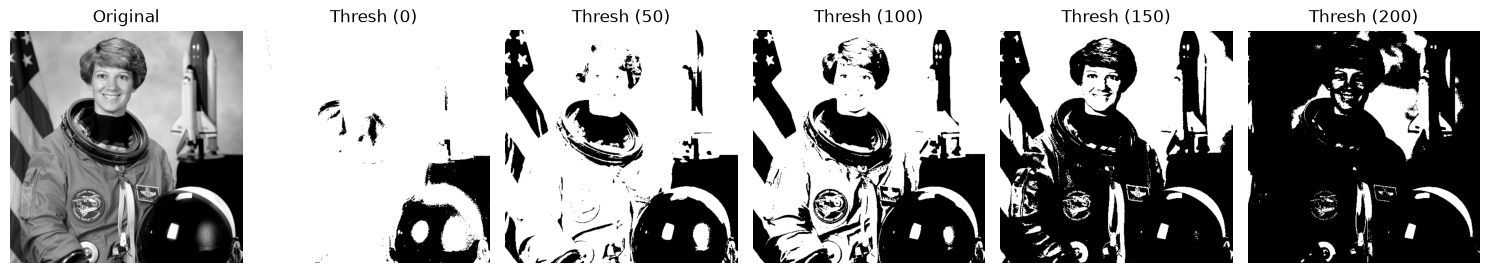

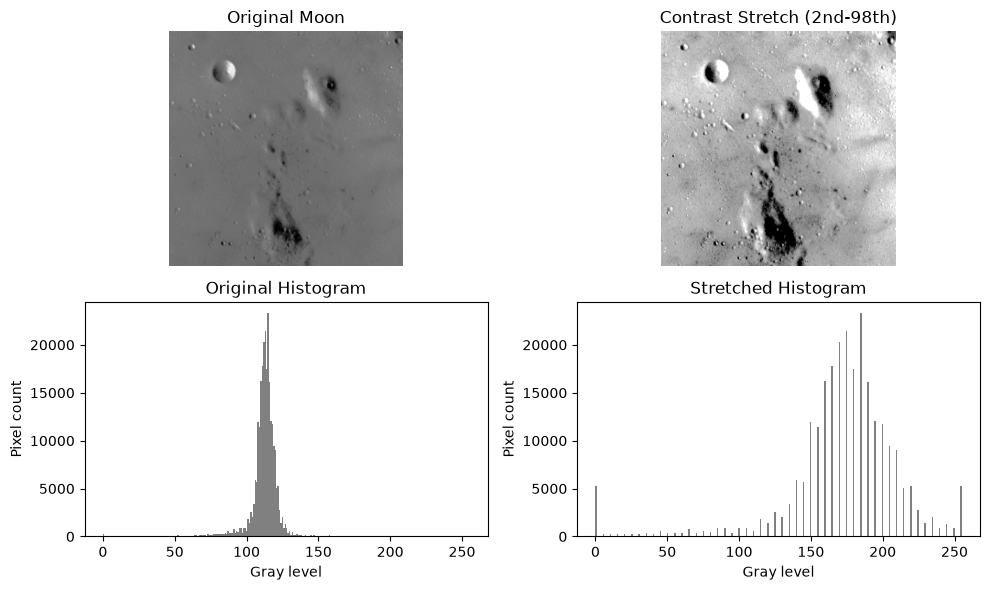

In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, exposure


os.makedirs('images', exist_ok=True)

test_img = data.astronaut()
cv2.imwrite('images/Parrot.png', cv2.cvtColor(test_img, cv2.COLOR_RGB2BGR))


img_gray = cv2.imread('images/Parrot.png', cv2.IMREAD_GRAYSCALE)
threshold_values = [0, 50, 100, 150, 200]

plt.figure(figsize=(15, 3))
plt.subplot(1, 6, 1)
plt.imshow(img_gray, cmap='gray')
plt.title('Original')
plt.axis('off')

for idx, t_val in enumerate(threshold_values, start=2):
    _, thresh = cv2.threshold(img_gray, t_val, 255, cv2.THRESH_BINARY)
    plt.subplot(1, 6, idx)
    plt.imshow(thresh, cmap='gray')
    plt.title(f'Thresh ({t_val})')
    plt.axis('off')

plt.tight_layout()
plt.show()


moon_img = data.moon()
p2, p98 = np.percentile(moon_img, (2, 98))
img_rescale_2_98 = exposure.rescale_intensity(moon_img, in_range=(p2, p98))

fig, axes = plt.subplots(2, 2, figsize=(10, 6))

axes[0, 0].imshow(moon_img, cmap='gray')
axes[0, 0].set_title('Original Moon')
axes[0, 0].axis('off')

axes[1, 0].hist(moon_img.flat, bins=256, range=(0, 255), color='gray')
axes[1, 0].set_title('Original Histogram')
axes[1, 0].set_xlabel('Gray level')
axes[1, 0].set_ylabel('Pixel count')

axes[0, 1].imshow(img_rescale_2_98, cmap='gray')
axes[0, 1].set_title('Contrast Stretch (2nd-98th)')
axes[0, 1].axis('off')

axes[1, 1].hist(img_rescale_2_98.flat, bins=256, range=(0, 255), color='gray')
axes[1, 1].set_title('Stretched Histogram')
axes[1, 1].set_xlabel('Gray level')
axes[1, 1].set_ylabel('Pixel count')

plt.tight_layout()
plt.show()

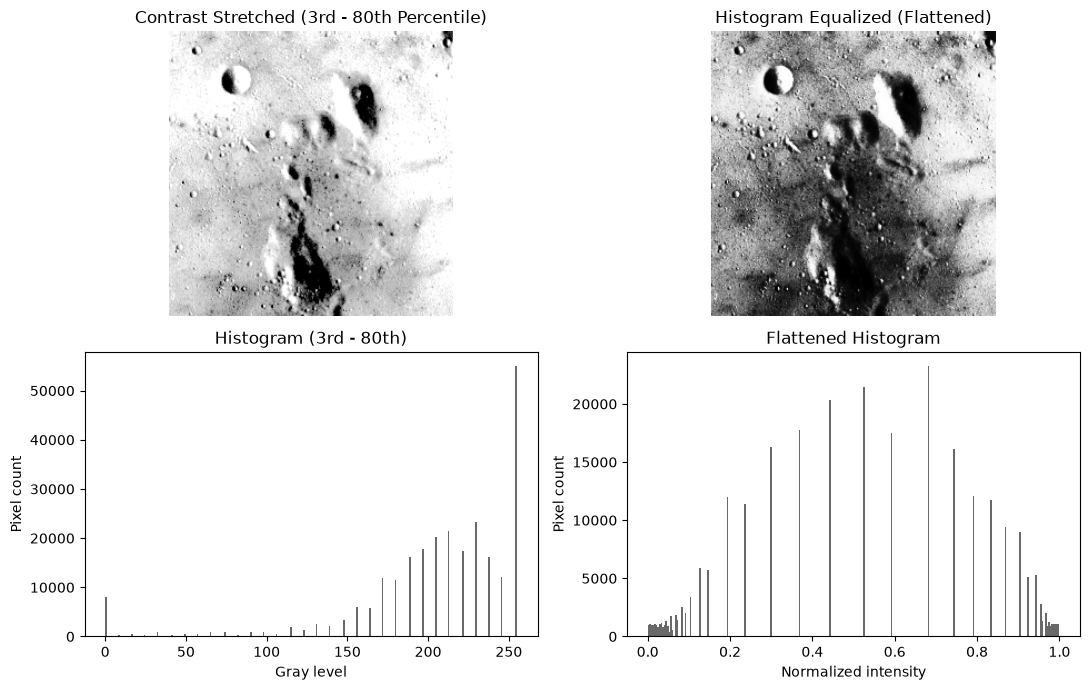

In [2]:

p3, p80 = np.percentile(moon_img, (3, 80))
img_rescale_3_80 = exposure.rescale_intensity(moon_img, in_range=(p3, p80))


img_eq = exposure.equalize_hist(moon_img)

fig, axes = plt.subplots(2, 2, figsize=(11, 7))

axes[0, 0].imshow(img_rescale_3_80, cmap='gray')
axes[0, 0].set_title('Contrast Stretched (3rd - 80th Percentile)')
axes[0, 0].axis('off')

axes[1, 0].hist(img_rescale_3_80.flat, bins=256, range=(0, 255), color='dimgray')
axes[1, 0].set_title('Histogram (3rd - 80th)')
axes[1, 0].set_xlabel('Gray level')
axes[1, 0].set_ylabel('Pixel count')


axes[0, 1].imshow(img_eq, cmap='gray')
axes[0, 1].set_title('Histogram Equalized (Flattened)')
axes[0, 1].axis('off')

axes[1, 1].hist(img_eq.flat, bins=256, range=(0.0, 1.0), color='dimgray')
axes[1, 1].set_title('Flattened Histogram')
axes[1, 1].set_xlabel('Normalized intensity')
axes[1, 1].set_ylabel('Pixel count')

plt.tight_layout()
plt.show()

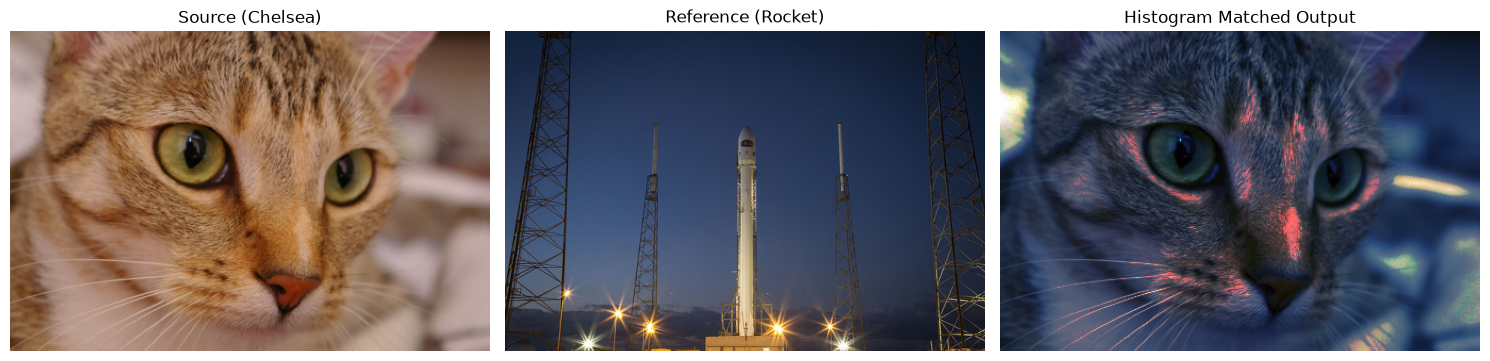

In [3]:

from skimage.exposure import match_histograms


source = data.chelsea()
reference = data.rocket()

matched = match_histograms(source, reference, channel_axis=-1)


fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(source)
axes[0].set_title('Source (Chelsea)')
axes[0].axis('off')

axes[1].imshow(reference)
axes[1].set_title('Reference (Rocket)')
axes[1].axis('off')

axes[2].imshow(matched)
axes[2].set_title('Histogram Matched Output')
axes[2].axis('off')

plt.tight_layout()
plt.show()